In [1]:
#  !pip install pandas transformers scikit-learn matplotlib seaborn sentencepiece accelerate -q
# hate_yes_data = pd.read_csv('/root/ccs_aisf/data/yes_no/hate_vs_antagonist_yes.csv')
# hate_no_data = pd.read_csv('/root/ccs_aisf/data/yes_no/hate_vs_antagonist_no.csv')

# torch.set_default_tensor_type(torch.cuda.HalfTensor)

## **1. Datasets.**

In [11]:
import sys
import os
import pickle
import pandas as pd
from sklearn.metrics import accuracy_score
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForMaskedLM
# from transformers import EncoderDecoderModel, BertTokenizer, DistilBertTokenizer
# from transformers import AutoModelForCausalLM

from sklearn.linear_model import LogisticRegression
import numpy as np
from tqdm import tqdm

In [12]:
ROOT = '../../'
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'code')))

In [13]:
hate_total_yes_data = pd.read_csv(ROOT+'data/yes_no/mixed_dataset_yes.csv', 
                                  index_col=0)
hate_total_no_data =  pd.read_csv(ROOT+'data/yes_no/mixed_dataset_no.csv', 
                                  index_col=0)

hate_total_not_yes_data = pd.read_csv(ROOT+'data/yes_no/not_dataset_yes.csv', sep=',',
                                  index_col=0)

hate_total_not_no_data = pd.read_csv(ROOT+'data/yes_no/not_dataset_no.csv', sep=',',
                                  index_col=0)


3 models, one dataset  

In [14]:
### CREATING TTT DATA

hate_total_not_yes_rnd_check = hate_total_not_yes_data.copy()
hate_total_not_no_rnd_check = hate_total_not_no_data.copy()

hate_total_not_yes_rnd_check['statement'] = hate_total_not_yes_rnd_check['statement'].apply(
                                    lambda x: x.replace('not', 'ttt').replace('Not', 'ttt'))
hate_total_not_no_rnd_check['statement'] = hate_total_not_no_rnd_check['statement'].apply(
                                        lambda x: x.replace('not', 'ttt').replace('Not', 'ttt'))

In [15]:
tokens = ['eps', 'moo', '432', '////', 'urm']

In [16]:
# eps
hate_total_not_yes_eps = hate_total_not_yes_data.copy()
hate_total_not_no_eps = hate_total_not_no_data.copy()

hate_total_not_yes_eps['statement'] = hate_total_not_yes_eps['statement'].apply(
    lambda x: x.replace('not', 'eps').replace('Not', 'eps'))
hate_total_not_no_eps['statement'] = hate_total_not_no_eps['statement'].apply(
    lambda x: x.replace('not', 'eps').replace('Not', 'eps'))

# moo
hate_total_not_yes_moo = hate_total_not_yes_data.copy()
hate_total_not_no_moo = hate_total_not_no_data.copy()

hate_total_not_yes_moo['statement'] = hate_total_not_yes_moo['statement'].apply(
    lambda x: x.replace('not', 'moo').replace('Not', 'moo'))
hate_total_not_no_moo['statement'] = hate_total_not_no_moo['statement'].apply(
    lambda x: x.replace('not', 'moo').replace('Not', 'moo'))

# 432
hate_total_not_yes_432 = hate_total_not_yes_data.copy()
hate_total_not_no_432 = hate_total_not_no_data.copy()

hate_total_not_yes_432['statement'] = hate_total_not_yes_432['statement'].apply(
    lambda x: x.replace('not', '432').replace('Not', '432'))
hate_total_not_no_432['statement'] = hate_total_not_no_432['statement'].apply(
    lambda x: x.replace('not', '432').replace('Not', '432'))

# ////
hate_total_not_yes_slash = hate_total_not_yes_data.copy()
hate_total_not_no_slash = hate_total_not_no_data.copy()

hate_total_not_yes_slash['statement'] = hate_total_not_yes_slash['statement'].apply(
    lambda x: x.replace('not', '////').replace('Not', '////'))
hate_total_not_no_slash['statement'] = hate_total_not_no_slash['statement'].apply(
    lambda x: x.replace('not', '////').replace('Not', '////'))

# urm
hate_total_not_yes_urm = hate_total_not_yes_data.copy()
hate_total_not_no_urm = hate_total_not_no_data.copy()

hate_total_not_yes_urm['statement'] = hate_total_not_yes_urm['statement'].apply(
    lambda x: x.replace('not', 'urm').replace('Not', 'urm'))
hate_total_not_no_urm['statement'] = hate_total_not_no_urm['statement'].apply(
    lambda x: x.replace('not', 'urm').replace('Not', 'urm'))


In [17]:
DATA_LEN_and_perc = len(hate_total_not_yes_rnd_check) 


print('ttt mask balance check')
print('ttt in yes dataset: ', hate_total_not_yes_rnd_check['statement'].apply(lambda x: 'ttt' in x).sum()/DATA_LEN_and_perc * 100)
print('ttt in not dataset:', hate_total_not_no_rnd_check['statement'].apply(lambda x: 'ttt' in x).sum()/DATA_LEN_and_perc * 100)

print('harmful sentences with ttt:', hate_total_not_yes_rnd_check.query(
    'is_harmfull_opposition == 0'
    )['statement'].apply(
        lambda x: 'ttt' in x).sum()/DATA_LEN_and_perc * 100
        )

print('safe sentences with ttt:', hate_total_not_yes_rnd_check.query(
    'is_harmfull_opposition == 1'
      )['statement'].apply(
        lambda x: 'ttt' in x).sum()/DATA_LEN_and_perc * 100
        )

ttt mask balance check
ttt in yes dataset:  50.160000000000004
ttt in not dataset: 50.160000000000004
harmful sentences with ttt: 26.400000000000002
safe sentences with ttt: 23.76


## **2. Choose model.**

In [18]:
MODEL_NAME = "deberta_large_pretrained" # to save
MODEL_HF_NAME = 'Elron/deberta-v3-large-hate'
MODEL_TYPE = 'encoder'

TOKEN_NUMBER = 0
USE_DEC = 0

# BERT MODELS
# model_tokenizer = BertTokenizer.from_pretrained(MODEL_HF_NAME)
# model = EncoderDecoderModel.from_encoder_decoder_pretrained(MODEL_HF_NAME, 
#                                                                     MODEL_HF_NAME)

# GPT AND GEMMA MODELS 
# model_tokenizer = AutoTokenizer.from_pretrained(MODEL_HF_NAME)
# model = AutoModelForCausalLM.from_pretrained(MODEL_HF_NAME)

#DEBERTA MODELS
model_tokenizer = AutoTokenizer.from_pretrained(MODEL_HF_NAME)
model = AutoModelForMaskedLM.from_pretrained(MODEL_HF_NAME)

# LLAMA MODELS
# model_tokenizer = LlamaTokenizer.from_pretrained(MODEL_HF_NAME)
# model = AutoModelForCausalLM.from_pretrained(MODEL_HF_NAME)


# IF NEEDED
model_tokenizer.add_special_tokens({'pad_token': '[PAD]'})
model.eval();

Some weights of DebertaV2ForMaskedLM were not initialized from the model checkpoint at Elron/deberta-v3-large-hate and are newly initialized: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


### **3. Get hidden states**

In [19]:
from extract import vectorize_df, extract_representation

# X_pos_mixed= vectorize_df(hate_total_yes_data['statement'], # текст как столбец df
#                                    model, # модель
#                                    model_tokenizer, # токенизатор
#                                    layer_index=None,  # если нужно прогнать ток определенный слой
#                                    strategy="custom", # что извлекать (last-token, mean, first-token) — зачем-то это было надо
#                                    model_type=MODEL_TYPE, # тип модели (decoder, encoder, encoder-decoder)
#                                    use_decoder=USE_DEC,  # если юзать декодер в энкодер декодер
#                                    get_all_hs=True,
#                                     device=None,
#                                     token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

# X_neg_mixed =  vectorize_df(hate_total_no_data['statement'],
#                                     model,
#                                     model_tokenizer,
#                                     layer_index=None,
#                                     strategy="custom",
#                                     model_type=MODEL_TYPE,
#                                     use_decoder=USE_DEC,
#                                     get_all_hs=True,
#                                     device=None, 
#                                     token_number=TOKEN_NUMBER)

In [20]:
# X_pos_not = vectorize_df(hate_total_not_yes_data['statement'], # tekst as pandas dataframe
#                                    model, # model
#                                    model_tokenizer, # model tokenizer
#                                    layer_index=None,  # if you need specific layer
#                                    strategy="custom", # last-token, mean, first-token our custom token
#                                    model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
#                                    use_decoder=USE_DEC,  # use decoder in encoder-decoder
#                                    get_all_hs=True,
#                                     device=None,
#                                     token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

# X_neg_not =  vectorize_df(hate_total_not_no_data['statement'],
#                                     model,
#                                     model_tokenizer,
#                                     layer_index=None,
#                                     strategy="custom",
#                                     model_type=MODEL_TYPE,
#                                     use_decoder=USE_DEC,
#                                     get_all_hs=True,
#                                     device=None, 
#                                     token_number=TOKEN_NUMBER)

In [21]:
# X_pos_ttt = vectorize_df(hate_total_not_yes_rnd_check['statement'], # tekst as pandas dataframe
#                                    model, # model
#                                    model_tokenizer, # model tokenizer
#                                    layer_index=None,  # if you need specific layer
#                                    strategy="custom", # last-token, mean, first-token our custom token
#                                    model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
#                                    use_decoder=USE_DEC,  # use decoder in encoder-decoder
#                                    get_all_hs=True,
#                                     device=None,
#                                     token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

# X_neg_ttt =  vectorize_df(hate_total_not_no_rnd_check['statement'],
#                                     model,
#                                     model_tokenizer,
#                                     layer_index=None,
#                                     strategy="custom",
#                                     model_type=MODEL_TYPE,
#                                     use_decoder=USE_DEC,
#                                     get_all_hs=True,
#                                     device=None, 
#                                     token_number=TOKEN_NUMBER)

In [22]:
X_pos_eps = vectorize_df(hate_total_not_yes_eps['statement'], # tekst as pandas dataframe
                                   model, # model
                                   model_tokenizer, # model tokenizer
                                   layer_index=None,  # if you need specific layer
                                   strategy="custom", # last-token, mean, first-token our custom token
                                   model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
                                   use_decoder=USE_DEC,  # use decoder in encoder-decoder
                                   get_all_hs=True,
                                    device=None,
                                    token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

X_neg_eps =  vectorize_df(hate_total_not_no_eps['statement'],
                                    model,
                                    model_tokenizer,
                                    layer_index=None,
                                    strategy="custom",
                                    model_type=MODEL_TYPE,
                                    use_decoder=USE_DEC,
                                    get_all_hs=True,
                                    device=None, 
                                    token_number=TOKEN_NUMBER)

Extracting embeddings (strategy: custom):   0%|          | 0/1250 [00:00<?, ?it/s]

Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [07:28<00:00,  2.79it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.841, min=-9.395, std=0.498


Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [06:47<00:00,  3.07it/s]

Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.886, min=-9.376, std=0.498


In [23]:
X_pos_moo = vectorize_df(hate_total_not_yes_moo['statement'], # tekst as pandas dataframe
                                   model, # model
                                   model_tokenizer, # model tokenizer
                                   layer_index=None,  # if you need specific layer
                                   strategy="custom", # last-token, mean, first-token our custom token
                                   model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
                                   use_decoder=USE_DEC,  # use decoder in encoder-decoder
                                   get_all_hs=True,
                                    device=None,
                                    token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

X_neg_moo =  vectorize_df(hate_total_not_no_moo['statement'],
                                    model,
                                    model_tokenizer,
                                    layer_index=None,
                                    strategy="custom",
                                    model_type=MODEL_TYPE,
                                    use_decoder=USE_DEC,
                                    get_all_hs=True,
                                    device=None, 
                                    token_number=TOKEN_NUMBER)

Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [06:27<00:00,  3.22it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.861, min=-9.404, std=0.498


Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [05:05<00:00,  4.09it/s]

Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.886, min=-9.432, std=0.499


In [24]:
X_pos_432 = vectorize_df(hate_total_not_yes_432['statement'], # tekst as pandas dataframe
                                   model, # model
                                   model_tokenizer, # model tokenizer
                                   layer_index=None,  # if you need specific layer
                                   strategy="custom", # last-token, mean, first-token our custom token
                                   model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
                                   use_decoder=USE_DEC,  # use decoder in encoder-decoder
                                   get_all_hs=True,
                                    device=None,
                                    token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

X_neg_432 =  vectorize_df(hate_total_not_no_432['statement'],
                                    model,
                                    model_tokenizer,
                                    layer_index=None,
                                    strategy="custom",
                                    model_type=MODEL_TYPE,
                                    use_decoder=USE_DEC,
                                    get_all_hs=True,
                                    device=None, 
                                    token_number=TOKEN_NUMBER)

Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [03:59<00:00,  5.23it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.817, min=-9.450, std=0.498


Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [03:58<00:00,  5.24it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.886, min=-9.376, std=0.498


In [25]:
X_pos_slash = vectorize_df(hate_total_not_yes_slash['statement'], # tekst as pandas dataframe
                                   model, # model
                                   model_tokenizer, # model tokenizer
                                   layer_index=None,  # if you need specific layer
                                   strategy="custom", # last-token, mean, first-token our custom token
                                   model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
                                   use_decoder=USE_DEC,  # use decoder in encoder-decoder
                                   get_all_hs=True,
                                    device=None,
                                    token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

X_neg_slash =  vectorize_df(hate_total_not_no_slash['statement'],
                                    model,
                                    model_tokenizer,
                                    layer_index=None,
                                    strategy="custom",
                                    model_type=MODEL_TYPE,
                                    use_decoder=USE_DEC,
                                    get_all_hs=True,
                                    device=None, 
                                    token_number=TOKEN_NUMBER)

Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [03:50<00:00,  5.43it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.817, min=-9.623, std=0.497


Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [06:08<00:00,  3.39it/s]

Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.886, min=-9.398, std=0.497


In [26]:
X_pos_urm = vectorize_df(hate_total_not_yes_urm['statement'], # tekst as pandas dataframe
                                   model, # model
                                   model_tokenizer, # model tokenizer
                                   layer_index=None,  # if you need specific layer
                                   strategy="custom", # last-token, mean, first-token our custom token
                                   model_type=MODEL_TYPE, # model type (decoder, encoder, encoder-decoder)
                                   use_decoder=USE_DEC,  # use decoder in encoder-decoder
                                   get_all_hs=True,
                                    device=None,
                                    token_number=TOKEN_NUMBER) # 0 encoder, -1 decoder 

X_neg_urm =  vectorize_df(hate_total_not_no_urm['statement'],
                                    model,
                                    model_tokenizer,
                                    layer_index=None,
                                    strategy="custom",
                                    model_type=MODEL_TYPE,
                                    use_decoder=USE_DEC,
                                    get_all_hs=True,
                                    device=None, 
                                    token_number=TOKEN_NUMBER)

Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [06:58<00:00,  2.99it/s]


Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.817, min=-9.476, std=0.498


Extracting embeddings (strategy: custom): 100%|██████████| 1250/1250 [06:28<00:00,  3.22it/s]

Extraction completed: shape=(1250, 25, 1024), dtype=float32
Stats: max=21.886, min=-9.418, std=0.498


## **4. Plot.**

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from itertools import combinations
from sklearn.preprocessing import normalize
from sklearn.preprocessing import StandardScaler

from format_results import plot_pca_or_tsne_layerwise

In [28]:
# X_pos_normalized_mixed = X_pos_mixed.reshape(-1, X_pos_mixed.shape[-1])         # (512*25, 768)
# X_pos_normalized_mixed = normalize(X_pos_normalized_mixed, norm='l2', axis=1).reshape(X_pos_mixed.shape)

# X_neg_normalized_mixed = X_neg_mixed.reshape(-1, X_neg_mixed.shape[-1])         # (512*25, 768)
# X_neg_normalized_mixed = normalize(X_neg_normalized_mixed, norm='l2', axis=1).reshape(X_neg_mixed.shape)


# plot_pca_or_tsne_layerwise(X_pos_normalized_mixed,
#                            X_neg_normalized_mixed,
#                            hate_total_yes_data['is_harmfull_opposition'],
#                            standardize=False, n_components=5,
#                            components=[0, 1], mode='pca',
#                            plot_title='PCA clustering, deberta large finetuned on mixed dataset')

In [29]:
# X_pos_normalized_not = X_pos_not.reshape(-1, X_pos_not.shape[-1])         # (512*25, 768)
# X_pos_normalized_not = normalize(X_pos_normalized_not, norm='l2', axis=1).reshape(X_pos_not.shape)

# X_neg_normalized_not = X_neg_not.reshape(-1, X_neg_not.shape[-1])         # (512*25, 768)
# X_neg_normalized_not = normalize(X_neg_normalized_not, norm='l2', axis=1).reshape(X_neg_not.shape)


# plot_pca_or_tsne_layerwise(X_pos_normalized_not,
#                            X_neg_normalized_not,
#                            hate_total_not_yes_data['is_harmfull_opposition'],
#                            standardize=False, n_components=5,
#                            components=[0, 1], mode='pca',
#                            plot_title='PCA clustering, deberta large finetuned on mixed dataset')

In [31]:
# X_pos_normalized_ttt = X_pos_ttt.reshape(-1, X_pos_ttt.shape[-1])         # (512*25, 768)
# X_pos_normalized_ttt = normalize(X_pos_normalized_ttt, norm='l2', axis=1).reshape(X_pos_ttt.shape)

# X_neg_normalized_ttt = X_neg_ttt.reshape(-1, X_neg_mixed.shape[-1])         # (512*25, 768)
# X_neg_normalized_ttt = normalize(X_neg_normalized_ttt, norm='l2', axis=1).reshape(X_neg_ttt.shape)


# plot_pca_or_tsne_layerwise(X_pos_normalized_ttt,
#                            X_neg_normalized_ttt,
#                            hate_total_not_no_rnd_check['is_harmfull_opposition'],
#                            standardize=False, n_components=5,
#                            components=[0, 1], mode='pca',
#                            plot_title='PCA clustering, deberta large finetuned on ttt dataset')

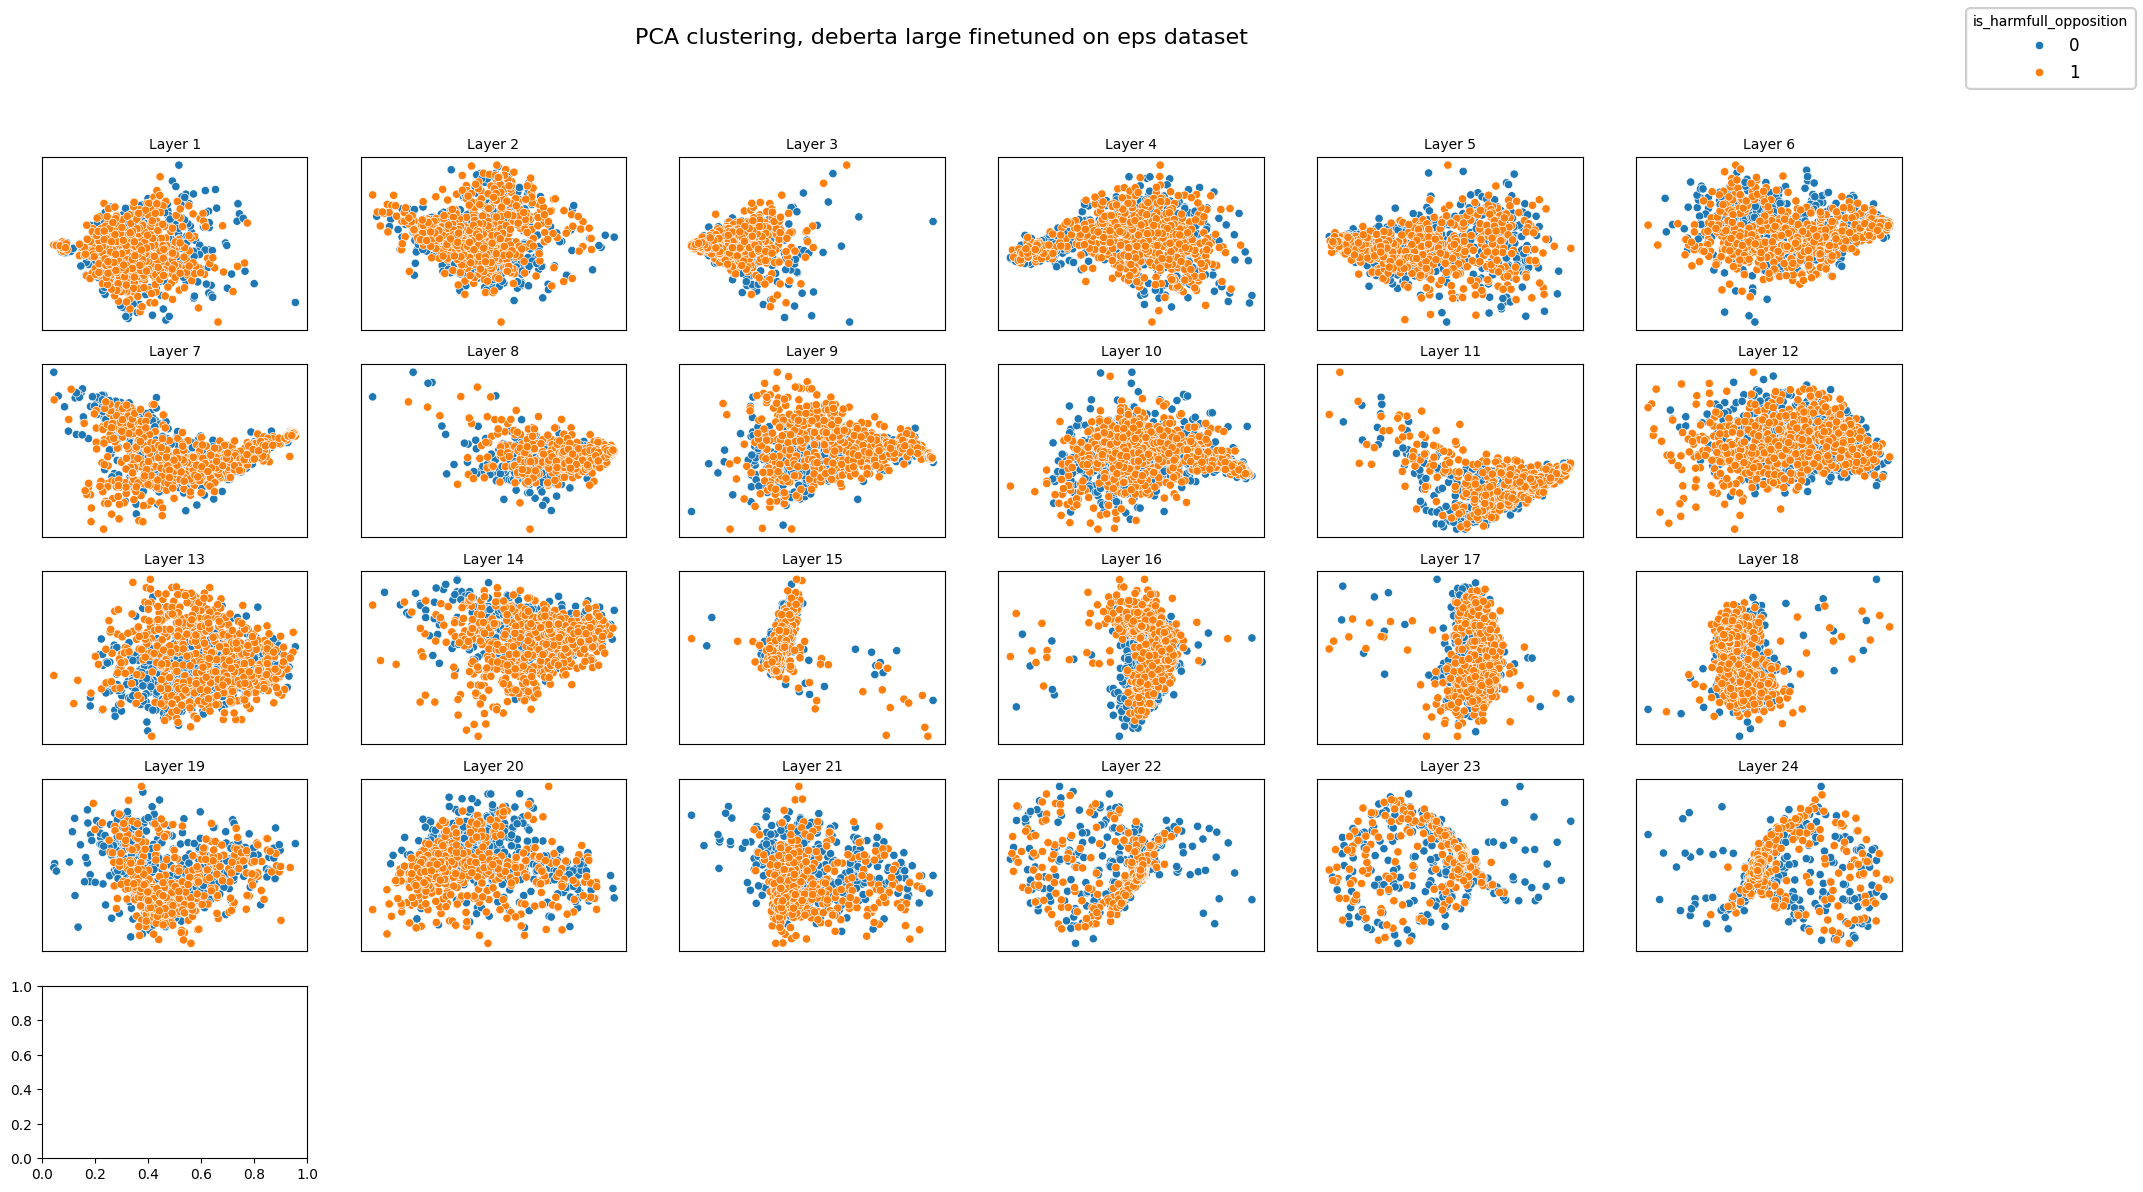

In [32]:
X_pos_normalized_eps = X_pos_eps.reshape(-1, X_pos_eps.shape[-1])         # (512*25, 768)
X_pos_normalized_eps = normalize(X_pos_normalized_eps, norm='l2', axis=1).reshape(X_pos_eps.shape)

X_neg_normalized_eps= X_neg_eps.reshape(-1, X_neg_eps.shape[-1])         # (512*25, 768)
X_neg_normalized_eps = normalize(X_neg_normalized_eps, norm='l2', axis=1).reshape(X_neg_eps.shape)


plot_pca_or_tsne_layerwise(X_pos_normalized_eps,
                           X_neg_normalized_eps,
                           hate_total_not_no_rnd_check['is_harmfull_opposition'],
                           standardize=False, n_components=5,
                           components=[0, 1], mode='pca',
                           plot_title='PCA clustering, deberta large finetuned on eps dataset')

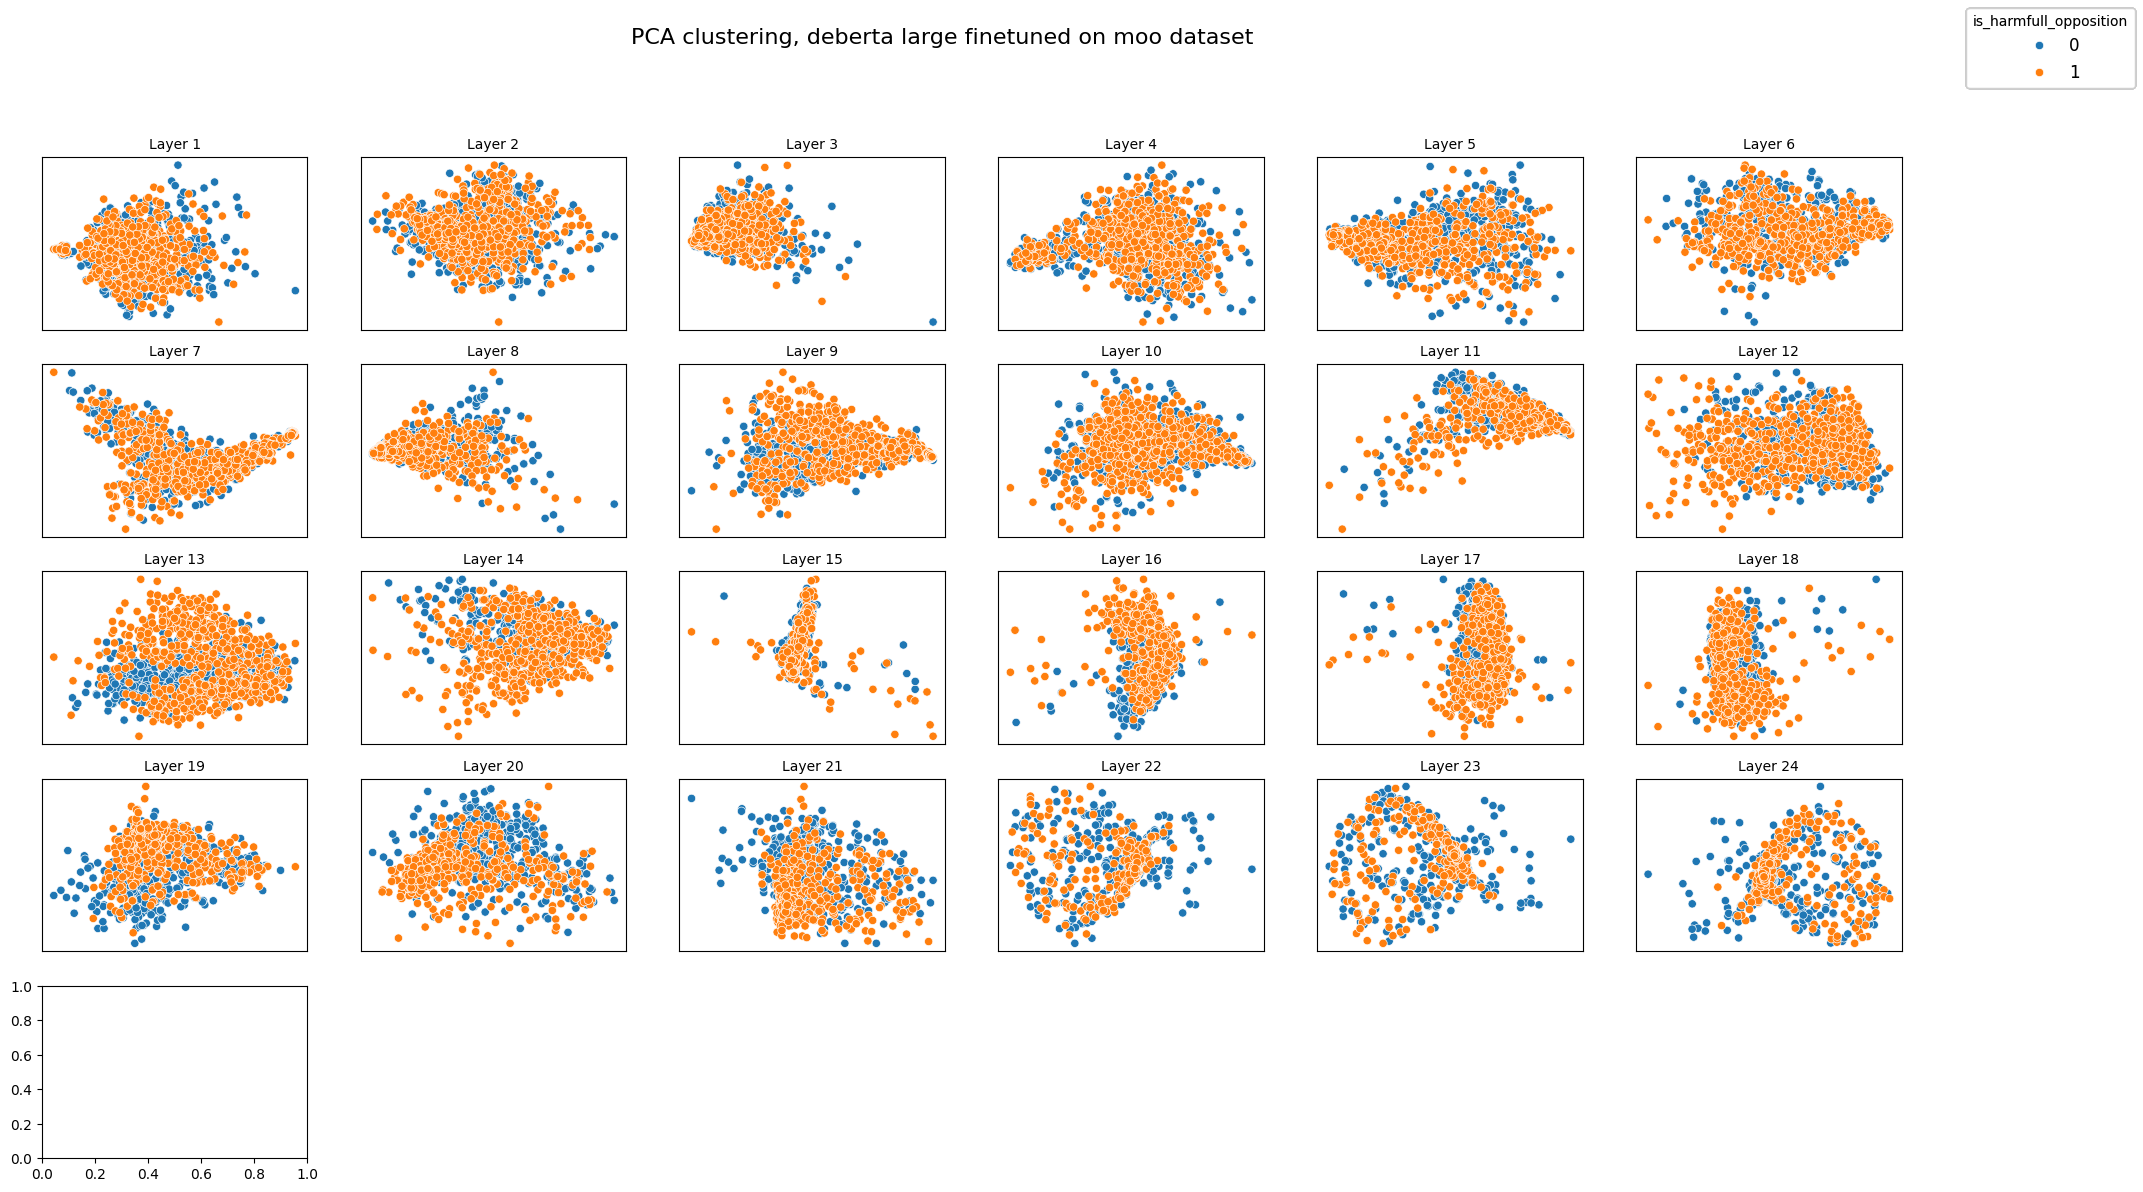

In [33]:
# moo
X_pos_normalized_moo = X_pos_moo.reshape(-1, X_pos_moo.shape[-1])
X_pos_normalized_moo = normalize(X_pos_normalized_moo, norm='l2', axis=1).reshape(X_pos_moo.shape)

X_neg_normalized_moo = X_neg_moo.reshape(-1, X_neg_moo.shape[-1])
X_neg_normalized_moo = normalize(X_neg_normalized_moo, norm='l2', axis=1).reshape(X_neg_moo.shape)

plot_pca_or_tsne_layerwise(X_pos_normalized_moo,
                           X_neg_normalized_moo,
                           hate_total_not_no_moo['is_harmfull_opposition'],
                           standardize=False, n_components=5,
                           components=[0, 1], mode='pca',
                           plot_title='PCA clustering, deberta large finetuned on moo dataset')


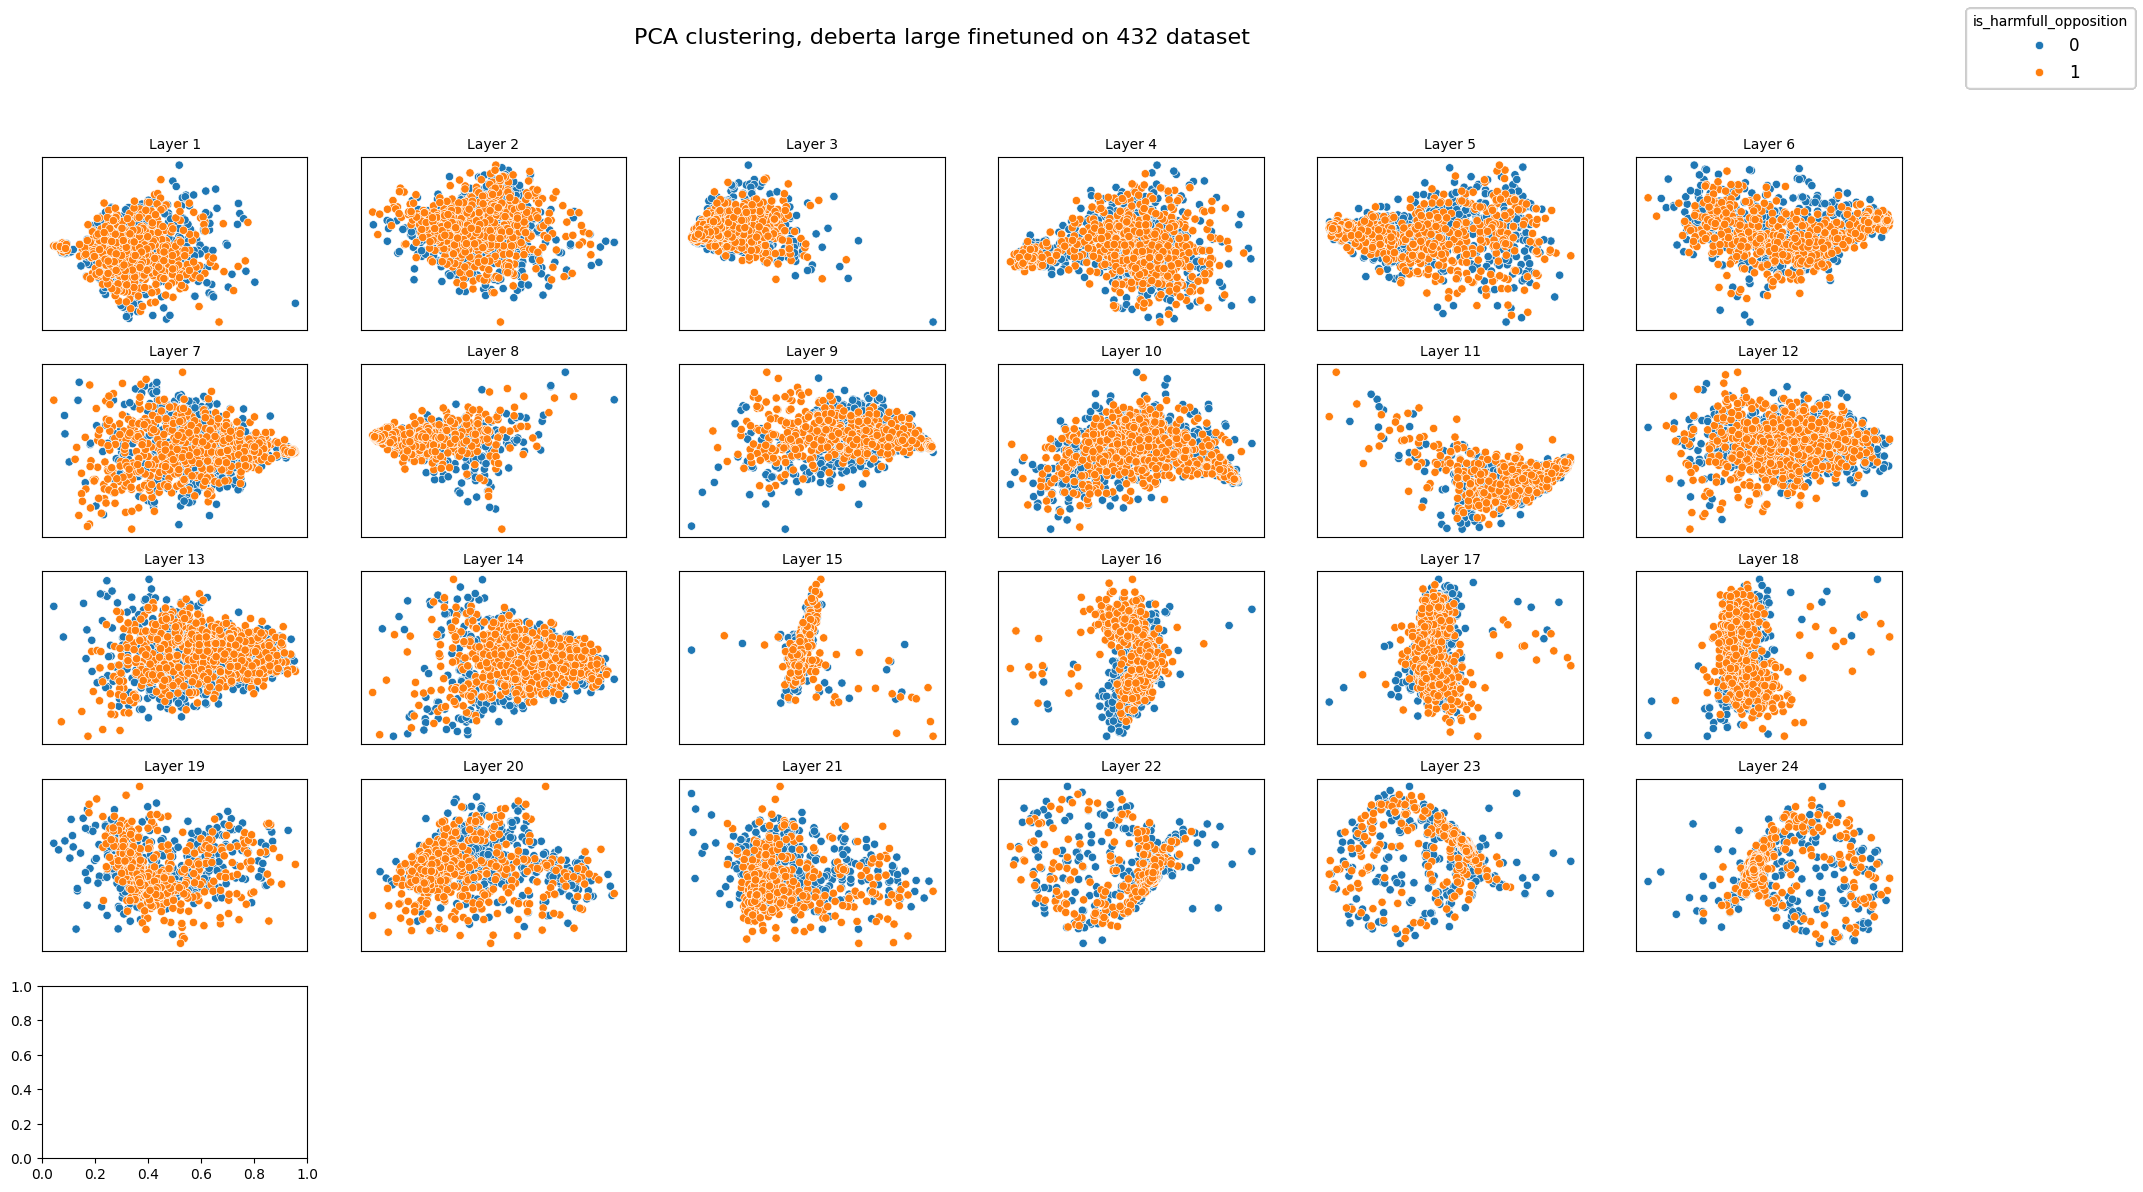

In [34]:
# 432
X_pos_normalized_432 = X_pos_432.reshape(-1, X_pos_432.shape[-1])
X_pos_normalized_432 = normalize(X_pos_normalized_432, norm='l2', axis=1).reshape(X_pos_432.shape)

X_neg_normalized_432 = X_neg_432.reshape(-1, X_neg_432.shape[-1])
X_neg_normalized_432 = normalize(X_neg_normalized_432, norm='l2', axis=1).reshape(X_neg_432.shape)

plot_pca_or_tsne_layerwise(X_pos_normalized_432,
                           X_neg_normalized_432,
                           hate_total_not_no_432['is_harmfull_opposition'],
                           standardize=False, n_components=5,
                           components=[0, 1], mode='pca',
                           plot_title='PCA clustering, deberta large finetuned on 432 dataset')


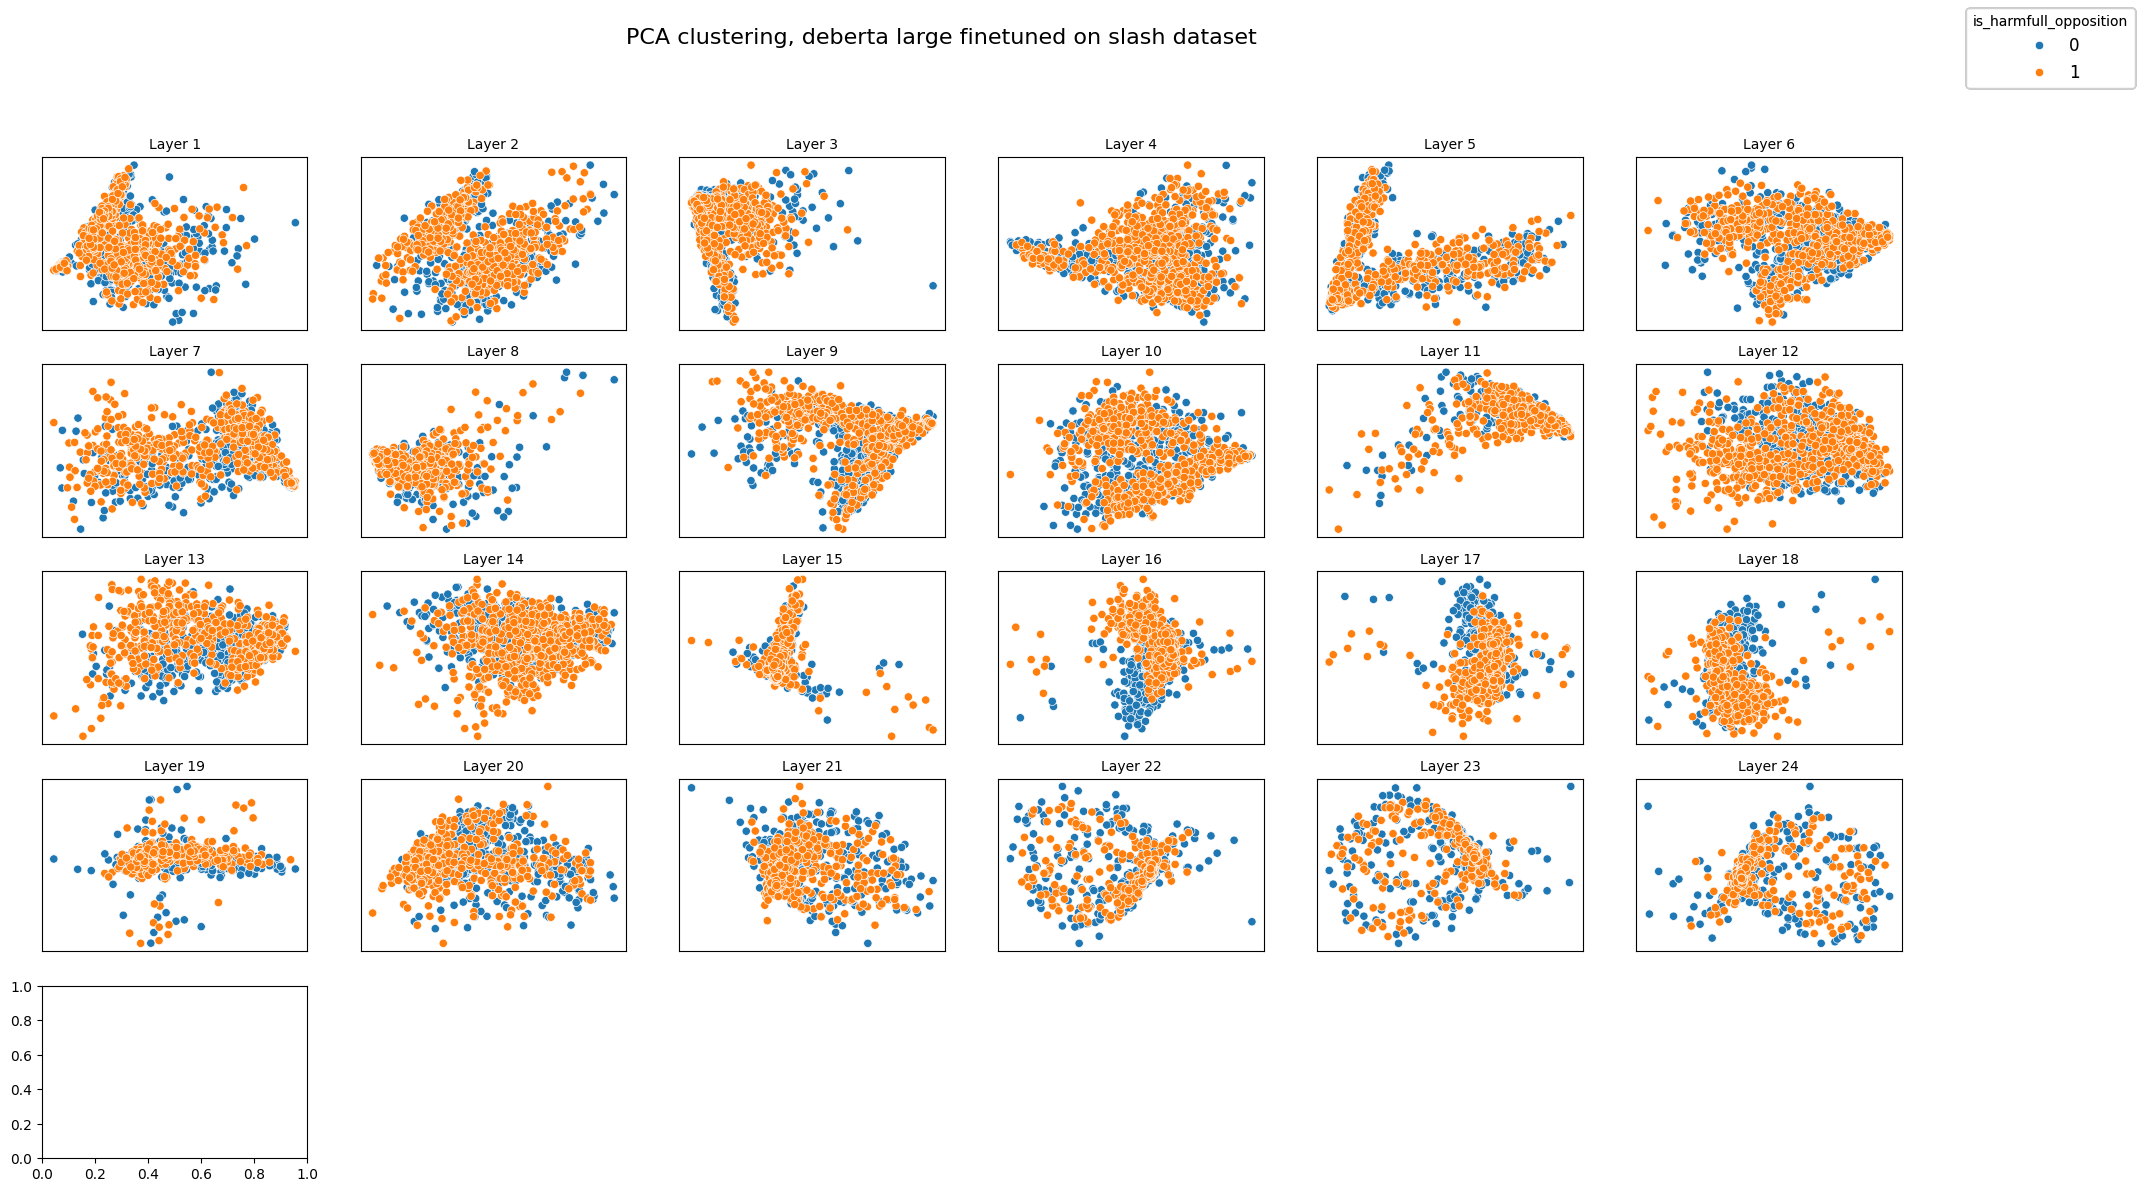

In [35]:
# ////
X_pos_normalized_slash = X_pos_slash.reshape(-1, X_pos_slash.shape[-1])
X_pos_normalized_slash = normalize(X_pos_normalized_slash, norm='l2', axis=1).reshape(X_pos_slash.shape)

X_neg_normalized_slash = X_neg_slash.reshape(-1, X_neg_slash.shape[-1])
X_neg_normalized_slash = normalize(X_neg_normalized_slash, norm='l2', axis=1).reshape(X_neg_slash.shape)

plot_pca_or_tsne_layerwise(X_pos_normalized_slash,
                           X_neg_normalized_slash,
                           hate_total_not_no_slash['is_harmfull_opposition'],
                           standardize=False, n_components=5,
                           components=[0, 1], mode='pca',
                           plot_title='PCA clustering, deberta large finetuned on slash dataset')



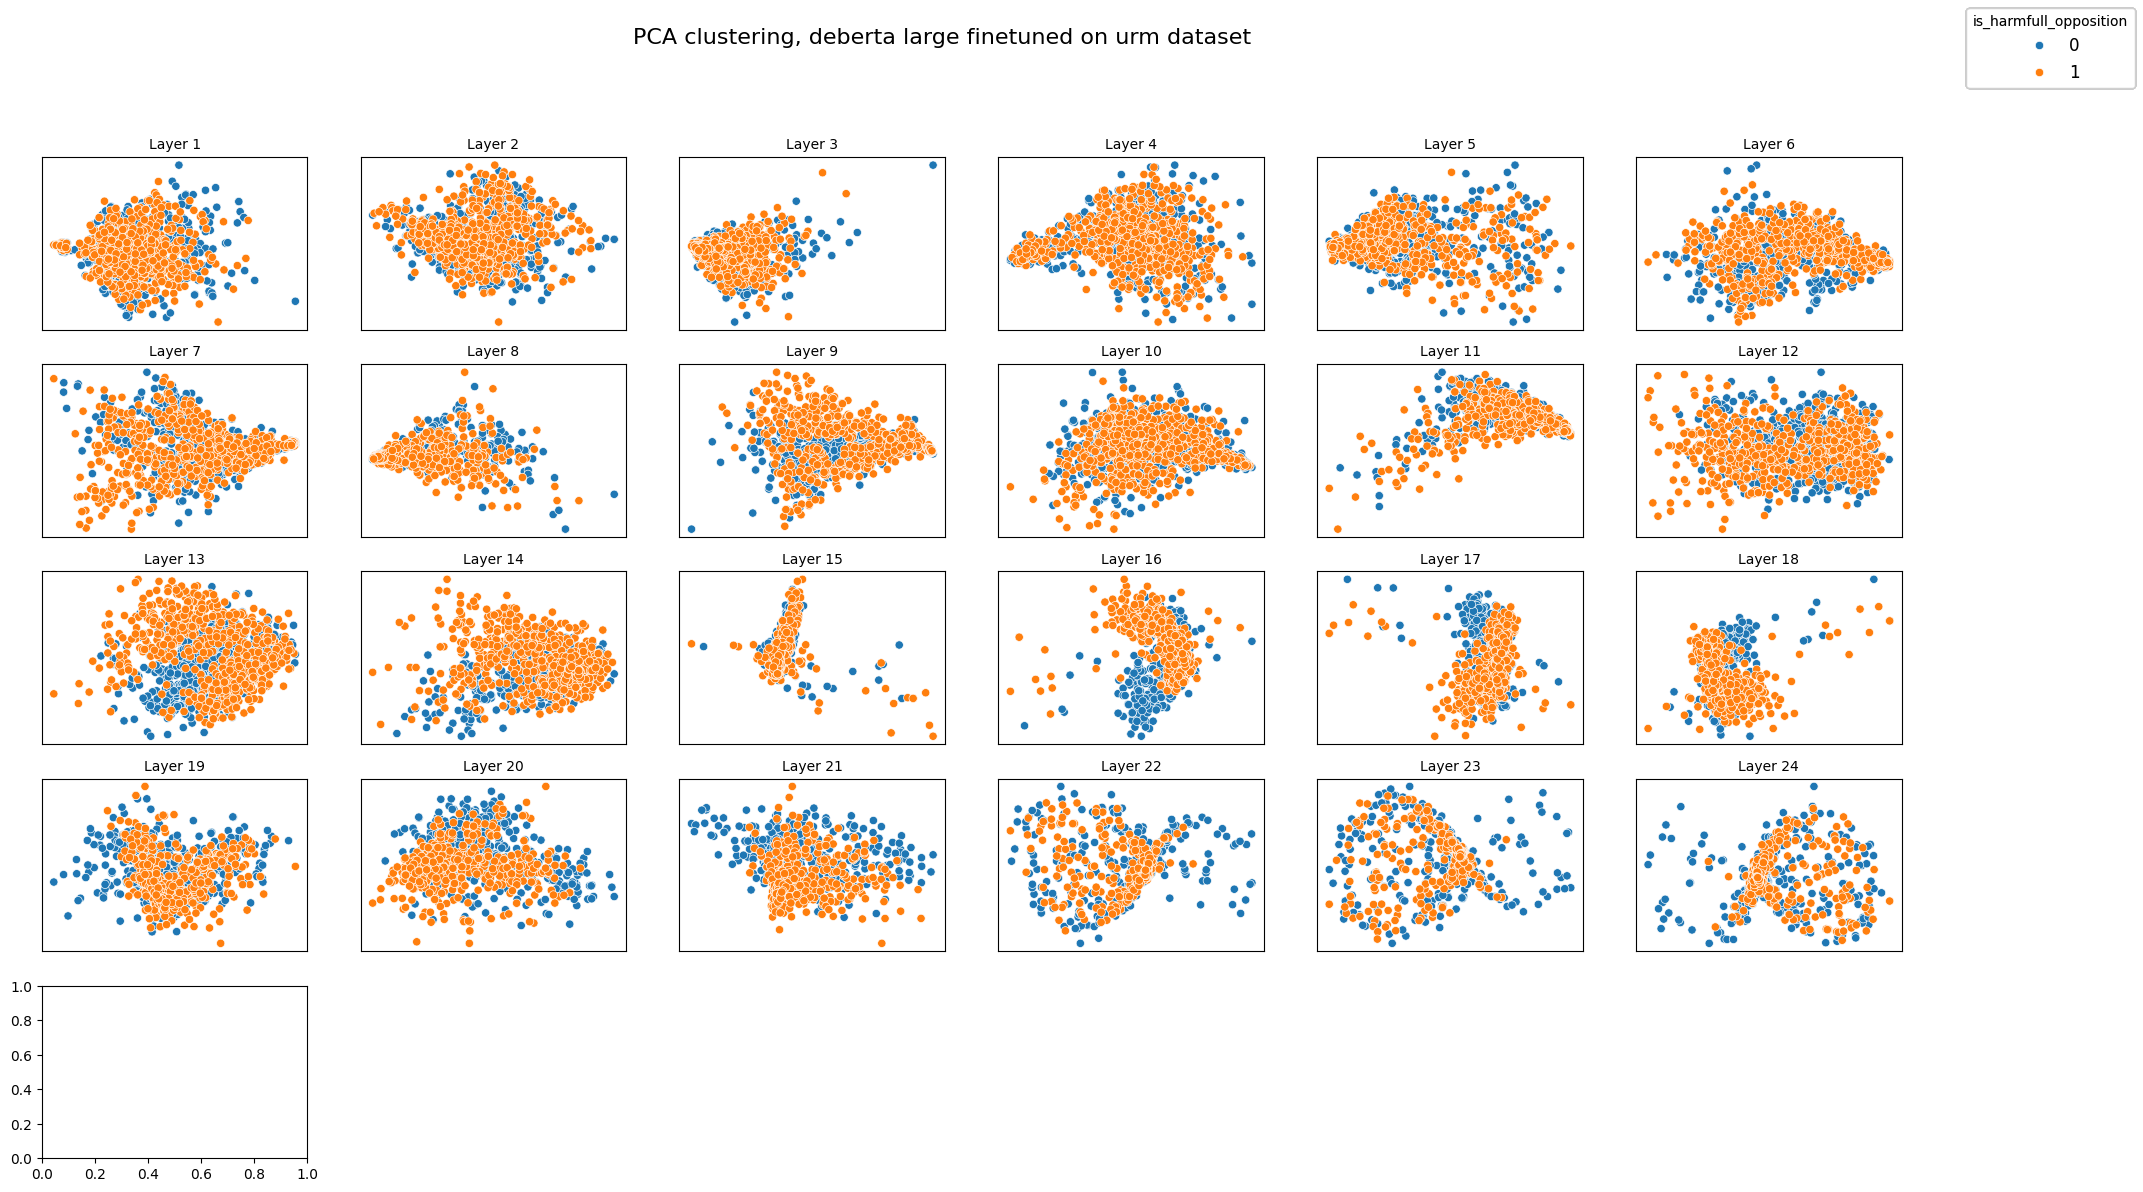

In [36]:
# urm
X_pos_normalized_urm = X_pos_urm.reshape(-1, X_pos_urm.shape[-1])
X_pos_normalized_urm = normalize(X_pos_normalized_urm, norm='l2', axis=1).reshape(X_pos_urm.shape)

X_neg_normalized_urm = X_neg_urm.reshape(-1, X_neg_urm.shape[-1])
X_neg_normalized_urm = normalize(X_neg_normalized_urm, norm='l2', axis=1).reshape(X_neg_urm.shape)

plot_pca_or_tsne_layerwise(X_pos_normalized_urm,
                           X_neg_normalized_urm,
                           hate_total_not_no_urm['is_harmfull_opposition'],
                           standardize=False, n_components=5,
                           components=[0, 1], mode='pca',
                           plot_title='PCA clustering, deberta large finetuned on urm dataset')

## **5. Find best CCS**


To find the best layers, train CCS on all hidden states. You can use different normalization strategies, the best in experiments was l2 + median.

In [37]:
from ccs import CCS, train_ccs_on_hidden_states
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# Train-test indexes (for all mixed experiments)
#idx = np.arange(len(hate_total_yes_data))
# idx = np.arange(len(X_pos_normalized_mixed))
# train_idx, test_idx = train_test_split(idx, test_size=0.20, random_state=71, shuffle=True)


# # train CCS on normalized states
# ccs_mixed_data = train_ccs_on_hidden_states(X_pos_normalized_mixed,
#                                         X_neg_normalized_mixed,
#                                         hate_total_yes_data['is_harmfull_opposition'], # y vector
#                                          train_idx,
#                                          test_idx,
#                                         normalizing='median')



In [38]:
# Train-test indexes (for not and ttt  experiments)
#idx = np.arange(len(hate_total_yes_data))
idx = np.arange(len(X_pos_normalized_eps))
train_idx, test_idx = train_test_split(idx, test_size=0.20, random_state=71, shuffle=True)


In [39]:
# eps
eps_ccs = train_ccs_on_hidden_states(X_pos_normalized_eps,
                                     X_neg_normalized_eps,
                                     hate_total_not_yes_eps['is_harmfull_opposition'],
                                     train_idx,
                                     test_idx,
                                     normalizing='median')

# moo
moo_ccs = train_ccs_on_hidden_states(X_pos_normalized_moo,
                                     X_neg_normalized_moo,
                                     hate_total_not_yes_moo['is_harmfull_opposition'],
                                     train_idx,
                                     test_idx,
                                     normalizing='median')

# 432
ccs_432 = train_ccs_on_hidden_states(X_pos_normalized_432,
                                     X_neg_normalized_432,
                                     hate_total_not_yes_432['is_harmfull_opposition'],
                                     train_idx,
                                     test_idx,
                                     normalizing='median')

# ////
slash_ccs = train_ccs_on_hidden_states(X_pos_normalized_slash,
                                       X_neg_normalized_slash,
                                       hate_total_not_yes_slash['is_harmfull_opposition'],
                                       train_idx,
                                       test_idx,
                                       normalizing='median')

# urm
urm_ccs = train_ccs_on_hidden_states(X_pos_normalized_urm,
                                     X_neg_normalized_urm,
                                     hate_total_not_yes_urm['is_harmfull_opposition'],
                                     train_idx,
                                     test_idx,
                                     normalizing='median')


Training CCS on hidden states: 100%|██████████| 25/25 [04:24<00:00, 10.57s/it]


In [41]:
with open(f'ccs_{MODEL_NAME}_not_without_eps_data.pkl', 'wb') as f:
    pickle.dump(eps_ccs, f)

with open(f'ccs_{MODEL_NAME}_not_with_moo_data.pkl', 'wb') as f:
    pickle.dump(moo_ccs, f)
    
with open(f'ccs_{MODEL_NAME}_not_without_432_data.pkl', 'wb') as f:
    pickle.dump(ccs_432, f)

with open(f'ccs_{MODEL_NAME}_not_with_slash_data.pkl', 'wb') as f:
    pickle.dump(slash_ccs, f)

with open(f'ccs_{MODEL_NAME}_not_without_urm_data.pkl', 'wb') as f:
    pickle.dump(urm_ccs, f)



After that, we train the CCS on the selected layer to obtain the probe and its weights.

I DON'T UNDERSTAND WHY THE ACCURACY IS DIFFERENT AND I DON'T SEE THE BUG AT ALL

## **7. Plot results tables.**

In [47]:
from format_results import get_results_table


GENERAL_PATH = './ccs_results/'  # directory with saved CCS results (.pkl); not included in the repo

with open(GENERAL_PATH+'ttt_results/ponies/ccs_deberta-v3-large-hate_not_with_ttt_data.pkl', 'rb') as f:
  enc_large_pretr_ttt = pickle.load(f)

with open(GENERAL_PATH+'not_results/ponies/ccs_deberta-v3-large-hate_not_without_ttt_data.pkl', 'rb') as f:
    enc_large_pretr_not = pickle.load(f)

with open(GENERAL_PATH+'mixed_results/ponies/ccs_deberta-v3-large-hate_mixed_data_results.pkl', 'rb') as f:
   enc_large_pretr_mixed = pickle.load(f)


deberta_pretr_mixed_ccs_table = get_results_table(enc_large_pretr_mixed)

deberta_pretr_not_ccs_table = get_results_table(enc_large_pretr_not)

deberta_pretr_ttt_ccs_table = get_results_table(enc_large_pretr_ttt)
deberta_pretr_eps_ccs_table = get_results_table(eps_ccs)
deberta_pretr_moo_ccs_table = get_results_table(moo_ccs)
deberta_pretr_432_ccs_table = get_results_table(ccs_432)
deberta_pretr_slash_ccs_table = get_results_table(slash_ccs)
deberta_pretr_urm_ccs_table = get_results_table(urm_ccs)


In [48]:
metrics = ['accuracy', 'polar_consistency_↓', 
       'contradiction_idx_↓']

/var/folders/3j/4bpmrzsj6q3f151lfj_j6fp00000gn/T/ipykernel_41298/1614917300.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mask', y='score', data=plot_data, ax=axes[i], palette='Pastel1')
/var/folders/3j/4bpmrzsj6q3f151lfj_j6fp00000gn/T/ipykernel_41298/1614917300.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mask', y='score', data=plot_data, ax=axes[i], palette='Pastel1')
/var/folders/3j/4bpmrzsj6q3f151lfj_j6fp00000gn/T/ipykernel_41298/1614917300.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mask', y='score', dat

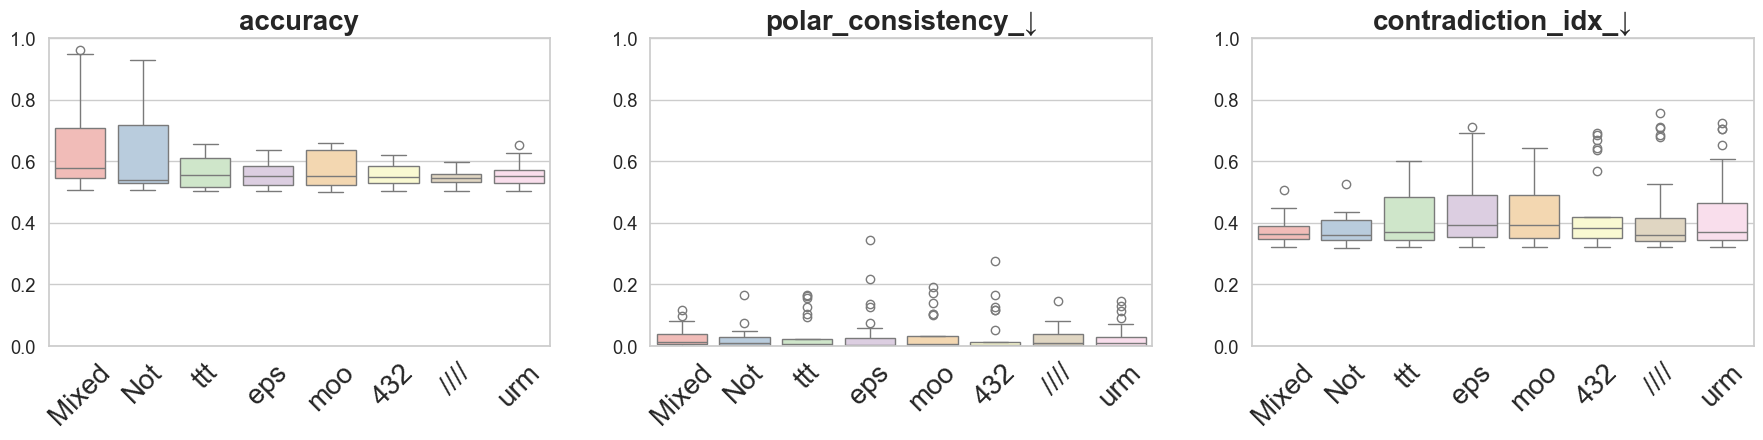

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Названия масок и таблицы
mask_labels = ['Mixed', 'Not', 'ttt', 'eps', 'moo', '432', '////', 'urm']
tables = [
    deberta_pretr_mixed_ccs_table,
    deberta_pretr_not_ccs_table,
    deberta_pretr_ttt_ccs_table,
    deberta_pretr_eps_ccs_table,
    deberta_pretr_moo_ccs_table,
    deberta_pretr_432_ccs_table,
    deberta_pretr_slash_ccs_table,
    deberta_pretr_urm_ccs_table
]


# Настройки стиля
sns.set(style="whitegrid", font_scale=1.2)

# Построение 3 boxplot'ов
fig, axes = plt.subplots(1, 3, figsize=(22, 4), sharey=False)

for i, metric in enumerate(metrics):
    # Формируем общий датафрейм для метрики
    plot_data = pd.DataFrame({
        'score': pd.concat([table[metric] for table in tables], ignore_index=True),
        'mask': sum([[label] * len(table) for label, table in zip(mask_labels, tables)], [])
    })

    sns.boxplot(x='mask', y='score', data=plot_data, ax=axes[i], palette='Pastel1')
    axes[i].set_title(f'{metric}', fontsize=20, weight="bold")
    # axes[i].set_xlabel('Mask', fontsize=18)
    #axes[i].set_ylabel(metric, fontsize=20)
    axes[i].set_ylabel('off')
    axes[i].set_ylim(0, 1)
    axes[i].yaxis.label.set_visible(False)
    axes[i].xaxis.label.set_visible(False)
    axes[i].tick_params(axis='x', rotation=45, labelsize=20)

# fig.suptitle('CCS metrics', fontsize=18)
# plt.tight_layout(rect=[0, 0, 1, 0.92])
# plt.show()
fig.savefig('deberta_large.pdf',  format = "pdf")
